#### Inference using model checkpoint

In [1]:
import json, os, logging
import pandas as pd
from tqdm import tqdm

import torch, transformers, sklearn, datasets
from datasets import Dataset

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

0. Utils

In [2]:
def generate_kmer(sequences: list, labels: list, k: int, overlap:int=1, distributed_training:bool=False, chunck_size=100000, logger: logging = logging):
    """
    Generate k-mer string from DNA sequence.
    """
    # utils
    def kmer(sequence: str, k: int, overlap: int):
        return " ".join([sequence[j:j+k] for j in range(0, len(sequence) - k + 1, overlap)])
    
    if not distributed_training:
        return [kmer(sequences[i], k, overlap) for i in range(len(sequences))], labels
    else:
        rank = torch.distributed.get_rank()
        world_size = torch.distributed.get_world_size()

        if rank == 0:
            kmer_seq = [kmer(sequences[i], k, overlap) for i in range(len(sequences))]
        else:
            kmer_seq = None 

        # broadcast k-mer data from rank 0 to all other ranks
        kmer_list = [kmer_seq]
        torch.distributed.broadcast_object_list(kmer_list, src=0)
        kmer_seq = kmer_list[0]  
        
        # partition the data among ranks
        total_size  = len(kmer_seq)
        start_idx   = rank * (total_size // world_size)
        end_idx     = (rank + 1) * (total_size // world_size) if rank != world_size - 1 else total_size
        kmer_subset = kmer_seq[start_idx:end_idx]
        label_subset = labels[start_idx:end_idx]
        logger.warning(f"Rank {rank}: Assigned data indices {start_idx} to {end_idx}")
        return kmer_subset, label_subset
    
def compute_and_display_metrics(predictions, true_labels, class_names=None):
    accuracy = accuracy_score(true_labels, predictions)
    precision = precision_score(true_labels, predictions, average='macro', zero_division=0)
    recall = recall_score(true_labels, predictions, average='macro', zero_division=0)
    f1 = f1_score(true_labels, predictions, average='macro', zero_division=0)
    conf_matrix = confusion_matrix(true_labels, predictions)

    # Prepare metrics dictionary
    metrics = {
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-Score": f1
    }
    
    # Print metrics
    print("Performance Metrics:")
    for key, value in metrics.items():
        print(f"{key}: {value:.4f}")
    
    # Display confusion matrix
    print("\nConfusion Matrix:")
    if class_names is None:
        class_names = [str(i) for i in range(len(conf_matrix))]
    
    df_cm = pd.DataFrame(conf_matrix, index=class_names, columns=class_names)
    plt.figure(figsize=(8, 6))
    sns.heatmap(df_cm, annot=True, fmt="d", cmap="Blues")
    plt.xlabel("Predicted Labels")
    plt.ylabel("True Labels")
    plt.title("Confusion Matrix")
    plt.show()
    
    # Print detailed classification report
    print("\nClassification Report:")
    print(classification_report(true_labels, predictions, target_names=class_names))

    return metrics

1. instanciate the model from checkpoint

In [3]:
checkpoint = "../finetune/output/BaBert_k6-CDS/checkpoint-27362"
device = torch.cuda.current_device() if torch.cuda.is_available() else 'cpu'

model = transformers.AutoModelForSequenceClassification.from_pretrained(
    checkpoint,
    num_labels=2,
    trust_remote_code=True,
).to(device)
tokenizer = transformers.AutoTokenizer.from_pretrained(
    checkpoint,
    model_max_length=252,
    padding_side="right",
    use_fast=True,
    trust_remote_code=True,
)

/home/mahouzonssou.akoteno/.local/lib/python3.8/site-packages/huggingface_hub/file_download.py:1150: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(


/home/mahouzonssou.akoteno/.conda/envs/dnabert/lib/python3.8/site-packages/transformers/modeling_utils.py:446: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  return torch.loa

2. Data Normal

In [4]:
with open('../data/cds/BacteriaCDS-ORFSeq2Class-v2/data_index.json', 'r') as file:
    index = json.load(file)

print(len(index["train"]))
print(len(index["dev"]))
print(len(index["test"]))

# --------------------------------------------------------------------------------
test_files = index["test"]
x = 10
merged_dfs = []
dfs = [pd.read_csv(f'../data/cds/BacteriaCDS-ORFSeq2Class-v2/database/{file}') for file in test_files[:x]]
df  = pd.concat(dfs, ignore_index=True)
sequences  = df['sequence'].values
labels     = df['label'].values
print(df.shape)
df.head()

4019
1148
575


(96094, 2)


,sequence,label
0,CTGTTATTAAAACCTACTTTCTTACAAATATCACTAATACTCATGC...,0
1,TTGATTGCTTACAACAAACTTAGCTTGAGTCCCATTAAATGTAACT...,0
2,TTGCTACTAGACCTAATTTTTTATCTTGTAAAAATACTTGTCCAAA...,0
3,ACTTGTTGTAAACAAATGGGTCTTGAAGATGAGAATGGTGAAATAA...,1
4,ATGTGGTCCATCTTAGCACAAGATTTTATAACTGCTGTAGGTCCAT...,0


In [5]:
sequences, labels = generate_kmer(sequences, labels, k=6, overlap=3)

batch_size = 256
predictions = []

for i in tqdm(range(0, len(sequences), batch_size), desc="Batch Prediction"):
    batch_sequences = sequences[i:i+batch_size]
    
    # tokenize the batch
    inputs = tokenizer(
        batch_sequences,
        return_tensors="pt",
        max_length=tokenizer.model_max_length,
        padding="max_length",
        truncation=True
    )
    inputs = {key: val.to(device) for key, val in inputs.items()}
    
    # predictions
    with torch.no_grad():
        outputs = model(**inputs)
        logits = outputs.logits
        predicted_classes = torch.argmax(logits, dim=-1).tolist()
    
    # Collect predictions
    predictions.extend(predicted_classes)

Batch Prediction:   0%|                                                                                                                                                                   | 0/376 [00:00<?, ?it/s]

Batch Prediction:   0%|▍                                                                                                                                                          | 1/376 [00:01<06:53,  1.10s/it]

Batch Prediction:   1%|▊                                                                                                                                                          | 2/376 [00:01<05:40,  1.10it/s]

Batch Prediction:   1%|█▏                                                                                                                                                         | 3/376 [00:02<05:16,  1.18it/s]

Batch Prediction:   1%|█▋                                                                                                                                                         | 4/376 [00:03<05:05,  1.22it/s]

...

Batch Prediction:  99%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████▊ | 373/376 [04:48<00:02,  1.29it/s]

Batch Prediction:  99%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████▏| 374/376 [04:49<00:01,  1.29it/s]

Batch Prediction: 100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████▌| 375/376 [04:50<00:00,  1.29it/s]

Batch Prediction: 100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 376/376 [04:50<00:00,  1.59it/s]

Batch Prediction: 100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 376/376 [04:50<00:00,  1.29it/s]

Performance Metrics:
Accuracy: 0.9938
Precision: 0.9814
Recall: 0.9889
F1-Score: 0.9851

Confusion Matrix:


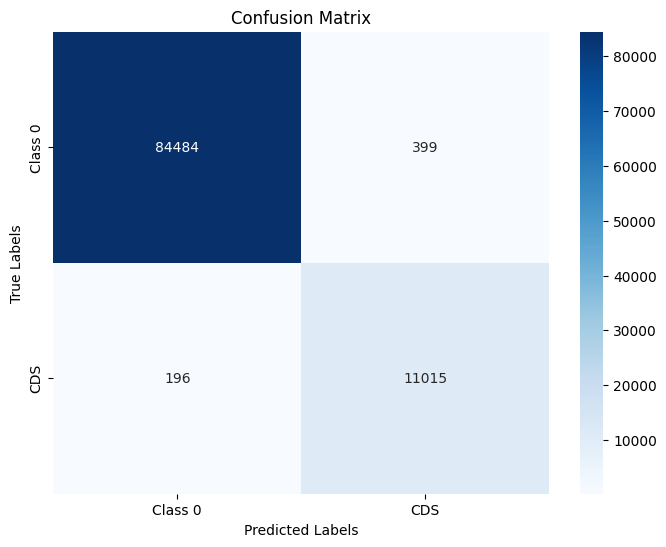


Classification Report:
              precision    recall  f1-score   support

     Class 0       1.00      1.00      1.00     84883
         CDS       0.97      0.98      0.97     11211

    accuracy                           0.99     96094
   macro avg       0.98      0.99      0.99     96094
weighted avg       0.99      0.99      0.99     96094



In [6]:
class_names = ["Class 0", "CDS"]
metrics = compute_and_display_metrics(predictions, labels, class_names=class_names)

3. Data Balanced

In [7]:
with open('../data/cds/BacteriaCDS-ORFSeq2Class-v2/data_index.json', 'r') as file:
    index = json.load(file)

print(len(index["train"]))
print(len(index["dev"]))
print(len(index["test"]))

# --------------------------------------------------------------------------------
test_files = index["test"]
x = 10
merged_dfs = []
dfs = [pd.read_csv(f'../data/cds/BacteriaCDS-ORFSeq2Class-v2/balanced/{file}') for file in test_files[0:x]]
df = pd.concat(dfs, ignore_index=True)
sequences  = df['sequence'].values
labels     = df['label'].values
print(df.shape)
df.head()

4019
1148
575


(22202, 2)


,sequence,label
0,GAACTATATGAAAAAATAAAAGGAAATAACTATGATGAAAAGTTAA...,1
1,GGAAAACACAGTAATAGATACGTACAATGTGCAAAAGTATTAAGAT...,1
2,TATATAAATATAGGAGCTAATAGTAGAATCTTGATATGTATATTTG...,1
3,CGGTTGGACCTATTAACCCTGTTGCTCCTGTTATTCCTATTCCTGT...,0
4,CTGAGTTTTGTAATTAAAGTTTCTTTTTTATCTATAGCTTTCTCAT...,0


In [8]:
sequences, labels = generate_kmer(sequences, labels, k=6, overlap=3)

batch_size = 256
predictions = []

for i in tqdm(range(0, len(sequences), batch_size), desc="Batch Prediction"):
    batch_sequences = sequences[i:i+batch_size]
    
    # tokenize the batch
    inputs = tokenizer(
        batch_sequences,
        return_tensors="pt",
        max_length=tokenizer.model_max_length,
        padding="max_length",
        truncation=True
    )
    inputs = {key: val.to(device) for key, val in inputs.items()}
    
    # predictions
    with torch.no_grad():
        outputs = model(**inputs)
        logits = outputs.logits
        predicted_classes = torch.argmax(logits, dim=-1).tolist()
    
    # Collect predictions
    predictions.extend(predicted_classes)

Batch Prediction:   0%|                                                                                                                                                                    | 0/87 [00:00<?, ?it/s]

Batch Prediction:   1%|█▊                                                                                                                                                          | 1/87 [00:00<01:11,  1.21it/s]

Batch Prediction:   2%|███▌                                                                                                                                                        | 2/87 [00:01<01:09,  1.22it/s]

Batch Prediction:   3%|█████▍                                                                                                                                                      | 3/87 [00:02<01:08,  1.23it/s]

Batch Prediction:   5%|███████▏                                                                                                                                                    | 4/87 [00:03<01:07,  1.23it/s]

...

Batch Prediction:  97%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████▋     | 84/87 [01:08<00:02,  1.23it/s]

Batch Prediction:  98%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████▍   | 85/87 [01:09<00:01,  1.23it/s]

Batch Prediction:  99%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████▏ | 86/87 [01:09<00:00,  1.23it/s]

Batch Prediction: 100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 87/87 [01:10<00:00,  1.34it/s]

Batch Prediction: 100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 87/87 [01:10<00:00,  1.23it/s]

Performance Metrics:
Accuracy: 0.9407
Precision: 0.9441
Recall: 0.9403
F1-Score: 0.9405

Confusion Matrix:


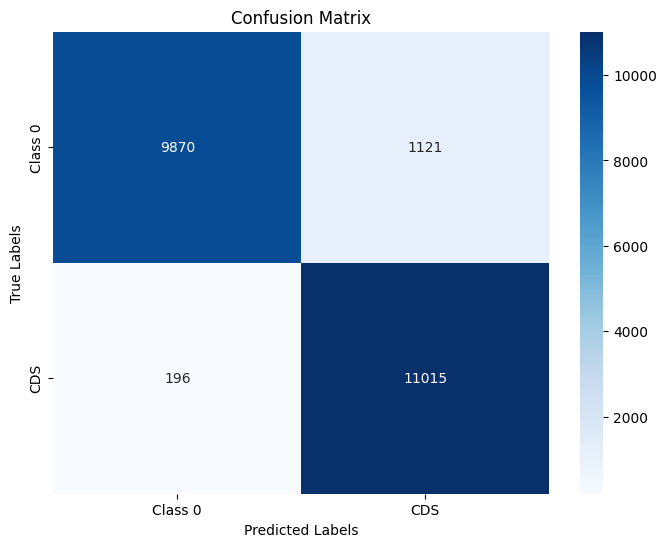


Classification Report:
              precision    recall  f1-score   support

     Class 0       0.98      0.90      0.94     10991
         CDS       0.91      0.98      0.94     11211

    accuracy                           0.94     22202
   macro avg       0.94      0.94      0.94     22202
weighted avg       0.94      0.94      0.94     22202



In [9]:
class_names = ["Class 0", "CDS"]
metrics = compute_and_display_metrics(predictions, labels, class_names=class_names)